# Vision Language Model Experiments – HAM10000

## Objective
This notebook explores Vision Language Models (VLMs) such as LLaVA
and Llama Vision using the HAM10000 image dataset.

The experiment focuses on generating general visual descriptions
of skin lesion images and studying the capabilities of multimodal
AI models.


In [1]:
import os
import base64
import requests
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from io import BytesIO

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define project paths
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"

METADATA_PATH = OUTPUT_DIR / "test.csv"

IMAGE_SIZE = (224, 224)

# Ollama local API
OLLAMA_URL = "http://localhost:11434"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project paths configured!")

Project paths configured!


In [3]:
# Load test dataset
test_df = pd.read_csv(METADATA_PATH)

print("Test dataset shape:", test_df.shape)
display(test_df.head())

Test dataset shape: (2014, 10)


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label,split
0,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0026769.jpg,2,Testing
1,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025661.jpg,2,Testing
2,HAM_0001396,ISIC_0025276,bkl,histo,55.0,female,trunk,..\data\HAM10000_images_part_1\ISIC_0025276.jpg,2,Testing
3,HAM_0007207,ISIC_0031326,bkl,histo,65.0,male,back,..\data\HAM10000_images_part_2\ISIC_0031326.jpg,2,Testing
4,HAM_0001773,ISIC_0024832,bkl,histo,40.0,female,face,..\data\HAM10000_images_part_1\ISIC_0024832.jpg,2,Testing


In [4]:
# Check whether Ollama is running
try:
    response = requests.get(
        f"{OLLAMA_URL}/api/tags",
        timeout=10
    )

    response.raise_for_status()

    ollama_data = response.json()

    available_models = [
        model["name"]
        for model in ollama_data.get("models", [])
    ]

    print("Ollama is running!")
    print("\nAvailable models:")

    for model in available_models:
        print("-", model)

except requests.exceptions.RequestException as error:
    print("Could not connect to Ollama.")
    print("Start Ollama and run this cell again.")
    print("Details:", error)

Ollama is running!

Available models:
- llava:7b
- mistral:latest
- llama3.2:3b


## Select a Vision Language Model

Ollama supports different multimodal models.
Examples include LLaVA and Llama Vision.

Only select a model that:
1. Is installed in Ollama.
2. Supports image input.
3. Can run with the available system memory.

Model availability and hardware requirements may vary.

In [5]:
OLLAMA_MODEL = "llava:7b"

print("Selected Vision Model:", OLLAMA_MODEL)

Selected Vision Model: llava:7b


Image path: ..\data\HAM10000_images_part_1\ISIC_0026769.jpg
Dataset class: bkl


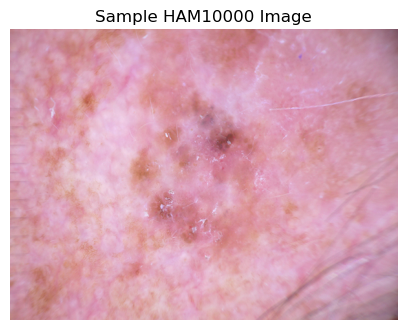

In [6]:
# Select one image from the test dataset
sample_row = test_df.iloc[0]

image_path = Path(sample_row["image_path"])

print("Image path:", image_path)
print("Dataset class:", sample_row["dx"])

# Display image
image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Sample HAM10000 Image")
plt.show()

In [7]:
# Convert image into Base64 format
with open(image_path, "rb") as image_file:
    encoded_image = base64.b64encode(
        image_file.read()
    ).decode("utf-8")

print("Image converted successfully!")

Image converted successfully!


## Generate Visual Description

The VLM will be asked to describe only general visual characteristics.

It must not infer a disease, malignancy, diagnosis, or medical risk.

In [8]:
# Define a visual description prompt
prompt = """
Describe only the visible visual characteristics of this image
for an educational computer vision dataset experiment.

Mention general colors, patterns, texture, and image quality.

Do not identify a disease, diagnose the image, estimate medical risk,
or recommend treatment.
"""

payload = {
    "model": OLLAMA_MODEL,
    "prompt": prompt,
    "images": [encoded_image],
    "stream": False
}

try:
    response = requests.post(
        f"{OLLAMA_URL}/api/generate",
        json=payload,
        timeout=300
    )

    response.raise_for_status()

    result = response.json()

    vlm_description = result.get("response", "")

    print("VLM Description:\n")
    print(vlm_description)

except requests.exceptions.RequestException as error:
    vlm_description = ""
    print("VLM request failed:", error)

VLM Description:

 The image shows a close-up of skin that appears to be affected by a skin condition or disease. The skin is discolored with patches of pink and yellow hues. There are visible lesions or spots, some of which are crusted, suggesting a possibility of infection or irritation. The background is not distinct enough to discern any specifics, but it is a uniform, muted tone that does not compete for attention with the skin condition. The texture of the skin looks bumpy and rough, with some smooth areas. The image quality is low, with a grainy appearance, which may be due to the camera or the nature of the photograph. The focus is on the skin condition, making it difficult to make out finer details that might be present in the background. 


In [9]:
# Store experiment details
vlm_result = pd.DataFrame([{
    "image_id": sample_row["image_id"],
    "metadata_class": sample_row["dx"],
    "model_name": OLLAMA_MODEL,
    "vlm_description": vlm_description
}])

# Save output
result_path = OUTPUT_DIR / "vlm_experiment_results.csv"

vlm_result.to_csv(result_path, index=False)

print("Experiment result saved to:", result_path)
display(vlm_result)

Experiment result saved to: ..\outputs\vlm_experiment_results.csv


,image_id,metadata_class,model_name,vlm_description
0,ISIC_0026769,bkl,llava:7b,The image shows a close-up of skin that appea...


# Conclusion

In this experiment, a Vision Language Model was explored using
HAM10000 image samples.

The model generated natural-language descriptions of visible
image characteristics.

This experiment demonstrates how multimodal AI models can be
explored alongside traditional CNN-based image classification.

The generated descriptions are not medical diagnoses and should
not be treated as clinical predictions.

In [11]:
# Configure the number of images
NUM_SAMPLES = 10

# Select sample records
sample_data = test_df.head(NUM_SAMPLES).copy()

batch_results = []

for index, row in sample_data.iterrows():

    image_path = Path(row["image_path"])

    print(f"Processing {index + 1}/{NUM_SAMPLES}: {row['image_id']}")

    try:
        # Convert image to Base64
        with open(image_path, "rb") as image_file:
            encoded_image = base64.b64encode(
                image_file.read()
            ).decode("utf-8")

        # Prepare prompt
        prompt = """
        Describe only the visible characteristics of this image
        for an educational computer vision experiment.

        Mention general colors, patterns, texture, and image quality.
        Do not provide a medical diagnosis or estimate medical risk.
        """

        payload = {
            "model": OLLAMA_MODEL,
            "prompt": prompt,
            "images": [encoded_image],
            "stream": False
        }

        # Send request to Ollama
        response = requests.post(
            f"{OLLAMA_URL}/api/generate",
            json=payload,
            timeout=300
        )

        response.raise_for_status()

        result = response.json()

        description = result.get("response", "")

        batch_results.append({
            "image_id": row["image_id"],
            "metadata_class": row["dx"],
            "model_name": OLLAMA_MODEL,
            "vlm_description": description,
            "status": "success"
        })

    except Exception as error:

        batch_results.append({
            "image_id": row["image_id"],
            "metadata_class": row["dx"],
            "model_name": OLLAMA_MODEL,
            "vlm_description": "",
            "status": f"failed: {str(error)}"
        })

# Convert results into DataFrame
batch_results_df = pd.DataFrame(batch_results)

display(batch_results_df)

Processing 1/10: ISIC_0026769
Processing 2/10: ISIC_0025661
Processing 3/10: ISIC_0025276
Processing 4/10: ISIC_0031326
Processing 5/10: ISIC_0024832
Processing 6/10: ISIC_0026958
Processing 7/10: ISIC_0030768
Processing 8/10: ISIC_0029837
Processing 9/10: ISIC_0028774
Processing 10/10: ISIC_0030565


,image_id,metadata_class,model_name,vlm_description,status
0,ISIC_0026769,bkl,llava:7b,The image you've provided appears to be a clo...,success
1,ISIC_0025661,bkl,llava:7b,The image shows a close-up of a skin conditio...,success
2,ISIC_0025276,bkl,llava:7b,The image shows a close-up view of a skin sur...,success
3,ISIC_0031326,bkl,llava:7b,The image appears to be a close-up view of a ...,success
4,ISIC_0024832,bkl,llava:7b,The image depicts a close-up of a person's le...,success
5,ISIC_0026958,bkl,llava:7b,The image displays a close-up of a portion of...,success
6,ISIC_0030768,bkl,llava:7b,"The image is quite close-up, focusing on a de...",success
7,ISIC_0029837,bkl,llava:7b,The image shows a close-up of a person's skin...,success
8,ISIC_0028774,bkl,llava:7b,The image you've provided appears to be a clo...,success
9,ISIC_0030565,bkl,llava:7b,The image shows a close-up view of a skin sur...,success


In [12]:
# Save batch experiment results
batch_output_path = OUTPUT_DIR / "vlm_batch_results.csv"

batch_results_df.to_csv(
    batch_output_path,
    index=False
)

print("Batch experiment completed!")
print("Results saved to:", batch_output_path)

print("\nProcessing summary:")
print(batch_results_df["status"].value_counts())

Batch experiment completed!
Results saved to: ..\outputs\vlm_batch_results.csv

Processing summary:
status
success    10
Name: count, dtype: int64


In [13]:
# Calculate description lengths
batch_results_df["description_length"] = (
    batch_results_df["vlm_description"].str.len()
)

# Display description statistics
display(
    batch_results_df[
        ["image_id", "metadata_class", "description_length", "status"]
    ]
)

print(
    "Average description length:",
    batch_results_df["description_length"].mean()
)

,image_id,metadata_class,description_length,status
0,ISIC_0026769,bkl,1372,success
1,ISIC_0025661,bkl,494,success
2,ISIC_0025276,bkl,429,success
3,ISIC_0031326,bkl,736,success
4,ISIC_0024832,bkl,624,success
5,ISIC_0026958,bkl,726,success
6,ISIC_0030768,bkl,457,success
7,ISIC_0029837,bkl,725,success
8,ISIC_0028774,bkl,682,success
9,ISIC_0030565,bkl,668,success


Average description length: 691.3


# Final Conclusion

The Vision Language Model experiment was conducted using LLaVA 7B.

The model generated natural-language descriptions for selected
HAM10000 test images.

The experiment demonstrates how multimodal models can provide
text-based descriptions of visual data.

These descriptions are exploratory outputs and are not validated
medical predictions or diagnostic results.

The CNN models and Vision Language Model serve different purposes:
- CNN models: Seven-class image classification.
- LLaVA: General natural-language image description.